# 12D — Multi-view latent athletic traits

**Part 1 · Research question (Q4).** Do several Combine drills, treated as measurement views, jointly reveal reproducible physical traits that single drill metrics measure unreliably?

**Part 2 · Declared hypotheses.** *Primary (reliability):* the shared factor scores of the multi-view model have higher attempt-split test–retest reliability than the most reliable single tracked feature loading on them (paired athlete bootstrap). *Secondary (transfer):* factor scores add held-out information beyond official tests (D0 = M1) and beyond the concatenated features (D1) for NFL acceleration / braking / distributional targets.

**Views and blocks.** Views = tracked drill families (`multiview_traits.VIEW_FAMILIES`) with ≤ 4 physics-preselected features each; official stopwatch tests are D0, never a view. Models: D2 probabilistic FA · D3 structured multi-view FA (shared + view-specific factors) · D4 D3 on position-centred features · D5 nonlinear variational model only if the declared support rule passes.

**Missingness.** Drill participation follows position and invitation — not missing at random. Factor scores use observed views only, missingness is diagnosed, complete cases are a sensitivity, and no score is read as ability in a drill the athlete did not perform. Factors are not named (e.g. explosiveness) unless loadings and stability support it.

**Prerequisites.** 12.0. 12C optional (adds its frozen target). Writes `m12d_selected_representation.json` (declared rule, no NFL value) used by 12C-M6 / 12G.

In [1]:
RUN_MODE = 'full'
SEED = 20261015
FORCE_REBUILD = False
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
MEMORY_BUDGET_GB = 2.0
RUN_BOOTSTRAP = True      # loading stability (fa_boot refits per model)

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement.artifacts import ResearchStore
from nflbdb.research.advanced_movement.m11 import config as m11c
from nflbdb.research.advanced_movement.m11 import sources as src
from nflbdb.research.advanced_movement.m11 import speed_state as ss
from nflbdb.research.advanced_movement.m12 import advanced_evaluation as ae
from nflbdb.research.advanced_movement.m12 import config as m12c
from nflbdb.research.advanced_movement.m12 import figures as fg
from nflbdb.research.advanced_movement.m12 import foundation as fd
from nflbdb.research.advanced_movement.m12 import multiview_traits as mv
from nflbdb.research.advanced_movement.m12 import reporting as rp
from nflbdb.research.advanced_movement.m12 import synthesis as sy
from nflbdb.research.advanced_movement.m12 import validation as v12

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = ResearchStore(cfg, controls)
amc.seed_everything(controls.seed)
C = m12c.M12Config().for_mode(controls)
S = src.M11Sources(cfg, store, m11c.M11Config().for_mode(controls))
D = fd.M12Data(store, C, S)
PROV = m12c.provenance('12D', controls, C)
W = store.write_frame
MAN = fd.check_foundation(store, C)
label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · config `{C.hash()}`'))
checks = v12.run_all((*v12.CHECKS_GENERAL, *v12.CHECKS_MULTIVIEW))
display(checks)
v12.assert_all_passed(checks)

**Run mode: `full`** (FULL) · config `c2903a12f8449fa2`

check,status,detail
str,str,str
"""grouped_folds_and_leakage""","""PASS""","""athlete-grouped folds enforced…"
"""block_sees_training_only""","""PASS""","""fold-fitted blocks receive one…"
"""common_cohort_pairing""","""PASS""","""every model of a ladder is sco…"
"""bootstrap_unit_and_seed""","""PASS""","""athlete bootstrap deterministi…"
"""checkpoint_resume_safety""","""PASS""","""completion gate blocks partial…"
"""evidence_tier_rules""","""PASS""","""evidence tiers never promote o…"
"""missing_view_factor_model""","""PASS""","""missing-view EM factor model r…"
"""structured_mask_and_alignment""","""PASS""","""structured multi-view mask and…"


## Part 3 · Data, views, availability and missingness

Athletes of the Combine registry with ≥ 2 tracked drill families (`elig_12D`). Folds: the 12.0 athlete folds; athletes without one (not linked to NFL) get a deterministic id-based fold so the unsupervised cross-fitting covers them — they never enter an NFL comparison.

In [3]:
reg = D.m12('m12_cohort_registry')
off, athf, att = D.officials(), D.athlete_features(), D.attempt_features()
POS = {int(i): p for i, p in zip(off['nfl_id'].to_list(), off['position_group'].to_list())}
views = mv.view_features(athf['feature'].unique().to_list())
elig = reg.filter(pl.col('elig_12D'))['nfl_id'].to_list()
ids, X, feats, views_of = mv.athlete_matrix(athf, views, elig)
pos = np.array([POS.get(int(i), '?') for i in ids])
fmap = dict(zip(*D.m12('m12_fold_manifest').select('nfl_id', 'fold').to_dict(as_series=False).values()))
folds = np.array([fmap.get(int(i), int(i) % C.outer_folds) if fmap.get(int(i)) is not None else int(i) % C.outer_folds for i in ids])
X1, X2 = mv.attempt_split_matrices(att, ids, feats)
display(ae.memory_plan([{'item': 'athlete × feature matrix', 'n_rows': X.shape[0], 'n_cols': X.shape[1]}], MEMORY_BUDGET_GB))
display(pl.DataFrame([{'view': v, 'features': ', '.join(fs)} for v, fs in views.items()]))
avail = mv.availability(ids, X, views_of, POS)
miss = mv.missingness_diagnostics(avail, off, list(views))
vae = mv.vae_feasible(avail, C)
W(avail, 'm12d_availability')
W(miss, 'm12d_missingness')
print(f'{ids.size} athletes · {len(feats)} features in {len(views)} views · D5:', vae['reason'])
with pl.Config(tbl_rows=-1, tbl_width_chars=220):
    display(miss)

item,n_rows,n_cols,est_mb,on_disk_mb,note,budget_mb,within_budget
str,i64,i64,f64,null,str,f64,bool
"""athlete × feature matrix""",510,20,0.1,null,"""""",2000.0,true


view,features
str,str
"""forty""","""forty.band_4_6_mean_accel, for…"
"""short_shuttle""","""short_shuttle.decel_mean, shor…"
"""three_cone""","""three_cone.transition_cost_ind…"
"""backpedal_transition""","""backpedal_transition.brake_to_…"
"""pass_rush""","""pass_rush.launch_accel, pass_r…"
"""gauntlet""","""gauntlet.sustained_speed, gaun…"


510 athletes · 20 features in 6 views · D5: only 0 athletes have every view (< 1000): D5 is not run — a declared rule, not a result


position_group,view,n,participation,smd_forty,smd_weight,smd_height
str,str,i64,f64,f64,f64,f64
"""DB""","""forty""",122,0.836066,NaN,-0.095718,-0.080865
"""DB""","""short_shuttle""",122,0.229508,-0.0507,0.239027,0.207419
"""DB""","""three_cone""",122,0.196721,-0.144023,0.387033,0.443871
"""DB""","""backpedal_transition""",122,0.918033,0.102311,-0.182358,-0.007882
"""DB""","""pass_rush""",122,0.0,NaN,NaN,NaN
"""DB""","""gauntlet""",122,0.97541,-0.635642,-0.007097,0.146267
"""DL""","""forty""",118,0.788136,NaN,0.019999,0.002268
"""DL""","""short_shuttle""",118,0.322034,0.304866,-0.185926,0.210832
"""DL""","""three_cone""",118,0.864407,0.429615,-0.316206,0.451765


## Part 4–6 · Physical definitions and models — dimensionality by held-out likelihood

Features are standardized with TRAINING-fold constants inside each fit. K is chosen per model by the held-out (athlete-fold) log-likelihood per observed value; nothing NFL-related enters.

In [4]:
ll = pl.concat([mv.heldout_loglik('D2', range(1, C.fa_max_k + 1), X, views_of, pos, folds, C, C.seed),
                mv.heldout_loglik('D3', range(1, min(3, C.fa_max_k) + 1), X, views_of, pos, folds, C, C.seed),
                mv.heldout_loglik('D4', range(1, min(3, C.fa_max_k) + 1), X, views_of, pos, folds, C, C.seed)])
W(ll, 'm12d_loglik')
display(ll)
BEST_K = {m: int(g.sort('heldout_loglik_per_value', descending=True)['k'][0]) for (m,), g in ll.partition_by(['model'], as_dict=True).items()}
print('K by held-out likelihood:', BEST_K)

C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\advanced_movement\m12\multiview_traits.py:237: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(ref, 0) if ref.shape[0] >= 5 else pooled


model,k,n_athletes,heldout_loglik_per_value
str,i64,i64,f64
"""D2""",1,510,-0.360086
"""D2""",2,510,-0.268655
"""D2""",3,510,-0.223962
"""D2""",4,510,-0.217184
"""D3""",1,510,-0.208935
"""D3""",2,510,-0.205423
"""D3""",3,510,-0.208012
"""D4""",1,510,-0.089016
"""D4""",2,510,-0.090479


K by held-out likelihood: {'D2': 4, 'D3': 2, 'D4': 1}


## Part 7a · Identification, stability and reliability (PRIMARY)

Full-data fits (display), shared / view-specific / unique variance, bootstrap loading congruence (Procrustes-aligned), position-specific loadings, and the cross-fitted attempt-split test–retest of factor scores vs the best single feature.

In [5]:
fits, retests, stab, posl = {}, [], [], []
for m, k in BEST_K.items():
    fits[m], Xin = mv.fit_model(m, k, X, views_of, pos, np.ones(ids.size, bool), C, C.seed)
    rt, ft = mv.latent_test_retest(m, k, ids, X, X1, X2, views_of, feats, pos, folds, C, C.seed)
    retests.append(rt)
    if RUN_BOOTSTRAP:
        stab.append(mv.bootstrap_stability(m, k, X, views_of, pos, C, C.seed))
    posl.append(mv.position_loadings(m, k, X, views_of, pos, C, C.seed).with_columns(pl.lit(m).alias('model')))
RET = pl.concat(retests, how='diagonal_relaxed')
STAB = pl.concat(stab) if stab else pl.DataFrame()
POSL = pl.concat([p for p in posl if p.height], how='diagonal_relaxed') if any(p.height for p in posl) else pl.DataFrame()
W(RET, 'm12d_retest')
W(ft, 'm12d_feature_retest')
W(STAB, 'm12d_bootstrap_stability')
W(POSL, 'm12d_position_loadings')
load = pl.concat([pl.DataFrame({'model': m, 'feature': feats, 'view': views_of, **{n: f.W[:, j] for j, n in enumerate(f.names)}, 'psi': f.psi}) for m, f in fits.items()], how='diagonal_relaxed')
vshare = pl.concat([pl.DataFrame({'model': m, 'feature': feats, 'shared': f.shared_variance_share()[:, 0], 'view_specific': f.shared_variance_share()[:, 1], 'unique': f.shared_variance_share()[:, 2]}) for m, f in fits.items()])
W(load, 'm12d_loadings')
W(vshare, 'm12d_variance_share')
# complete-case sensitivity: athletes with every view that ≥ 80 % of their position performs
typ = {p: [v for v in views if v in g.columns and g[v].mean() >= 0.8] for (p,), g in avail.partition_by(['position_group'], as_dict=True).items()}
cc = np.array([all(r[v] for v in typ.get(r['position_group'], [])) for r in avail.iter_rows(named=True)])
cc_rows = []
for m, k in BEST_K.items():
    if cc.sum() >= 50:
        fcc, _ = mv.fit_model(m, k, X[cc], views_of, pos[cc], np.ones(int(cc.sum()), bool), C, C.seed)
        ks = [j for j, n in enumerate(fits[m].names) if n.startswith('shared')]
        B_ = mv.procrustes(fits[m].W[:, ks], fcc.W[:, ks]) if len(ks) > 1 else fcc.W[:, ks]
        cc_rows += [{'model': m, 'factor': f'shared{q}', 'n_complete': int(cc.sum()), 'tucker_vs_all': mv.tucker(fits[m].W[:, ks][:, q], B_[:, q])} for q in range(len(ks))]
CC = pl.DataFrame(cc_rows)
W(CC, 'm12d_complete_case')
sel = mv.selection_rule(RET, ll)
if controls.save_tables and sel.get('model'):
    store.write_json('m12d_selected_representation', {**sel, 'rule': mv.selection_rule.__doc__.strip(), 'config_hash': C.hash(), 'features': feats, 'views': views_of})
with pl.Config(tbl_rows=-1, tbl_width_chars=240):
    display(RET)
    display(STAB.group_by('model', 'factor').agg(pl.col('tucker').median().alias('median_tucker'), pl.col('tucker').quantile(0.05).alias('q05_tucker')) if STAB.height else STAB)
    display(POSL)
    display(CC)
print('selected representation (declared rule, no NFL value):', sel)

model,k,factor,n_athletes,retest_factor,best_feature,retest_best_feature,gain,gain_lo,gain_hi
str,i64,str,i64,f64,str,f64,f64,f64,f64
"""D2""",4,"""shared0""",375,0.64184,"""forty.v_max_obs""",0.985491,-0.34365,-0.42283,-0.278715
"""D2""",4,"""shared1""",375,0.434476,"""forty.v_max_obs""",0.985491,-0.551014,-0.651242,-0.449213
"""D2""",4,"""shared2""",137,0.704094,"""gauntlet.sustained_speed""",0.740933,-0.036839,-0.070059,-0.002554
"""D2""",4,"""shared3""",375,0.318183,"""forty.band_6_8_mean_accel""",0.850348,-0.532165,-0.607563,-0.437687
"""D3""",2,"""shared0""",375,0.813177,"""forty.v_max_obs""",0.985491,-0.172314,-0.225109,-0.128677
"""D3""",2,"""shared1""",375,0.607871,"""forty.v_max_obs""",0.985491,-0.377619,-0.465543,-0.271431
"""D4""",1,"""shared0""",375,0.620111,"""forty.v_max_obs""",0.985491,-0.365379,-0.457166,-0.277977


model,factor,median_tucker,q05_tucker
str,str,f64,f64
"""D2""","""shared3""",0.934954,0.726681
"""D3""","""shared1""",0.878849,0.651151
"""D2""","""shared1""",0.968461,0.804647
"""D4""","""shared0""",0.934754,0.060788
"""D3""","""shared0""",0.953996,0.892517
"""D2""","""shared2""",0.983261,0.657581
"""D2""","""shared0""",0.975164,0.871191


position_group,factor,n_athletes,n_features,tucker,model
str,str,i64,i64,f64,str
"""DB""","""shared0""",122,17,0.439541,"""D2"""
"""DB""","""shared1""",122,17,0.845903,"""D2"""
"""DB""","""shared2""",122,17,0.90963,"""D2"""
"""DB""","""shared3""",122,17,0.883809,"""D2"""
"""DL""","""shared0""",118,17,0.667688,"""D2"""
"""DL""","""shared1""",118,17,0.602042,"""D2"""
"""DL""","""shared2""",118,17,0.768601,"""D2"""
"""DL""","""shared3""",118,17,0.68882,"""D2"""
"""OL""","""shared0""",121,14,0.848141,"""D2"""


model,factor,n_complete,tucker_vs_all
str,str,i64,f64
"""D2""","""shared0""",425,0.996797
"""D2""","""shared1""",425,0.992869
"""D2""","""shared2""",425,0.998118
"""D2""","""shared3""",425,0.997741
"""D3""","""shared0""",425,0.994763
"""D3""","""shared1""",425,0.993793
"""D4""","""shared0""",425,0.995598


selected representation (declared rule, no NFL value): {'model': 'D3', 'k': 2, 'mean_retest': 0.710524167926039, 'candidates': [('D3', 2, 0.710524167926039), ('D4', 1, 0.6201112089048244), ('D2', 4, 0.5246484557918731)]}


## Part 7b · NFL transfer (secondary)

Linked athletes only. D0 = M1 (officials) · D1 = M1 + every view feature (train-median imputation + missing indicators) · D2 / D3 / D4 = M1 + fold-fitted shared factor scores. Identical athletes per target; targets: 12C frozen `nfl.q90_shared` (when executed), `nfl.band_4_6`, `env.lin_A0` (acceleration capacity), `nfl.brake_decel` (braking).

In [6]:
nw = ss.nfl_wide(D.nfl_targets())
envw = ss.envelope_wide(D.envelopes(), 'lin').select('nfl_id', 'env.lin_A0')
tgts = nw.join(envw, on='nfl_id', how='full', coalesce=True)
if store.has('m12c_targets'):
    tgts = tgts.join(store.read_frame('m12c_targets', fd.NB['12C']).select('nfl_id', 'nfl.q90_shared'), on='nfl_id', how='full', coalesce=True)
fman = D.m12('m12_fold_manifest').select('nfl_id', 'fold')
featw = pl.DataFrame({'nfl_id': ids, **{f: X[:, j] for j, f in enumerate(feats)}})
linked = reg.filter(pl.col('linked'))['nfl_id'].to_list()
data = off.filter(pl.col('nfl_id').is_in(linked)).join(featw, on='nfl_id', how='inner').join(tgts, on='nfl_id', how='left').join(fman, on='nfl_id', how='inner').sort('nfl_id')
MODELS = {'D0': ae.Model(list(ae.M1_COLS)), 'D1': ae.Model([*ae.M1_COLS, *feats])}
for m, k in BEST_K.items():
    MODELS[m] = ae.Model(list(ae.M1_COLS), factory=lambda a, _m=m, _k=k: mv.factor_block(_m, _k, ids, X, views_of, POS, a, C, C.seed))
TR = []
for tg in [t for t in ('nfl.q90_shared', 'nfl.band_4_6', 'env.lin_A0', 'nfl.brake_decel') if t in data.columns]:
    res = ae.oof_ladder(data, tg, MODELS, C, C.seed)
    TR.append(ae.compare(res, [(m, 'D0') for m in MODELS if m != 'D0'] + [(m, 'D1') for m in BEST_K], C, C.seed, target=tg))
TR = pl.concat([t for t in TR if t.height], how='diagonal_relaxed') if TR else pl.DataFrame()
W(TR, 'm12d_transfer')
with pl.Config(tbl_rows=-1, tbl_width_chars=240):
    display(TR.select('target', 'model', 'reference', 'n_athletes', 'delta_rmse', 'delta_lo', 'delta_hi', 'verdict') if TR.height else TR)

target,model,reference,n_athletes,delta_rmse,delta_lo,delta_hi,verdict
str,str,str,i64,f64,f64,f64,str
"""nfl.q90_shared""","""D1""","""D0""",291,-0.003438,-0.011986,0.005064,"""inconclusive"""
"""nfl.q90_shared""","""D2""","""D0""",291,-0.001135,-0.00286,0.00075,"""inconclusive"""
"""nfl.q90_shared""","""D3""","""D0""",291,-0.000359,-0.001662,0.000922,"""inconclusive"""
"""nfl.q90_shared""","""D4""","""D0""",291,-0.000357,-0.001072,0.000411,"""inconclusive"""
"""nfl.q90_shared""","""D2""","""D1""",291,0.002303,-0.005704,0.010608,"""inconclusive"""
"""nfl.q90_shared""","""D3""","""D1""",291,0.003079,-0.005114,0.011215,"""inconclusive"""
"""nfl.q90_shared""","""D4""","""D1""",291,0.003082,-0.005286,0.011505,"""inconclusive"""
"""nfl.band_4_6""","""D1""","""D0""",280,-0.002596,-0.009311,0.004854,"""inconclusive"""
"""nfl.band_4_6""","""D2""","""D0""",280,0.00131,-0.002044,0.004786,"""inconclusive"""


## Part 8–9 · Uncertainty and figures

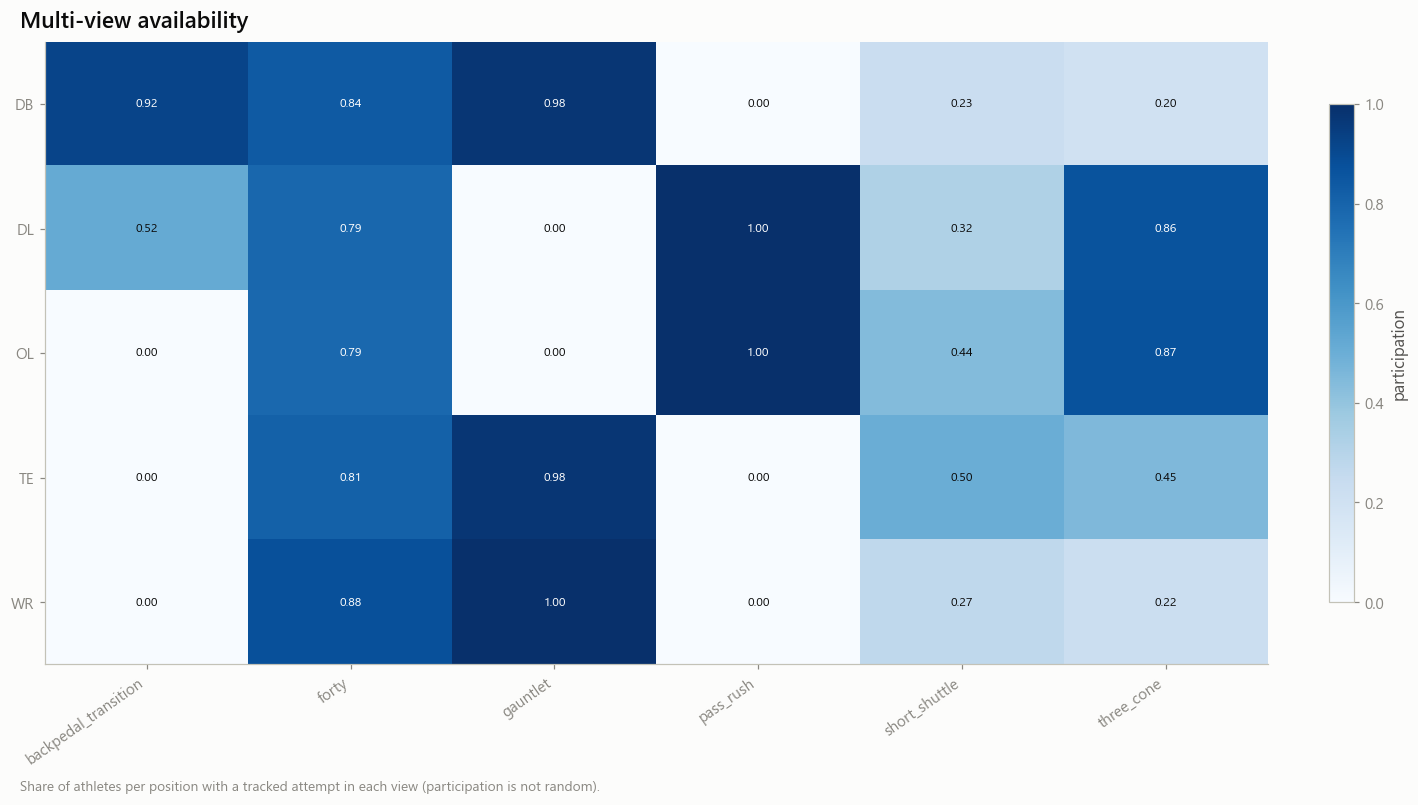

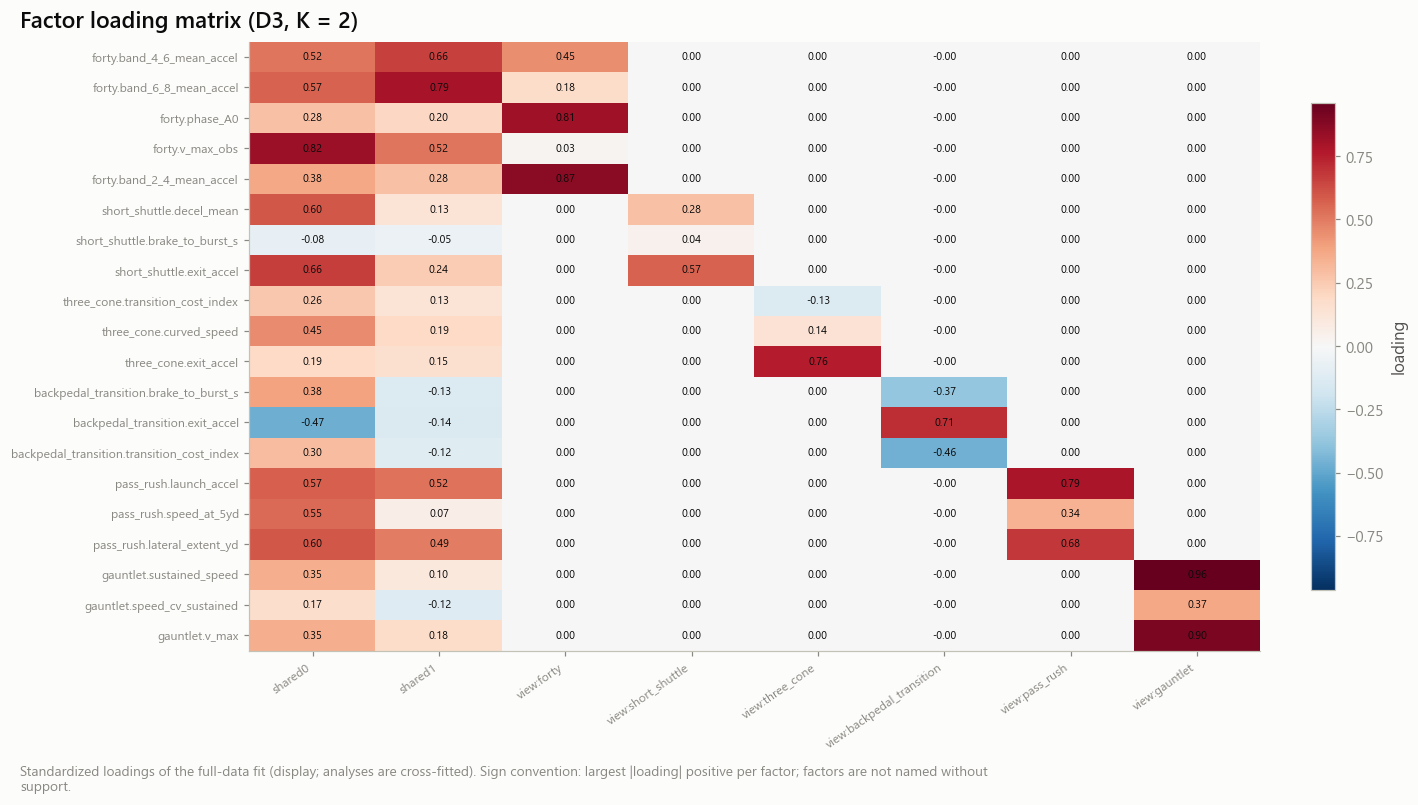

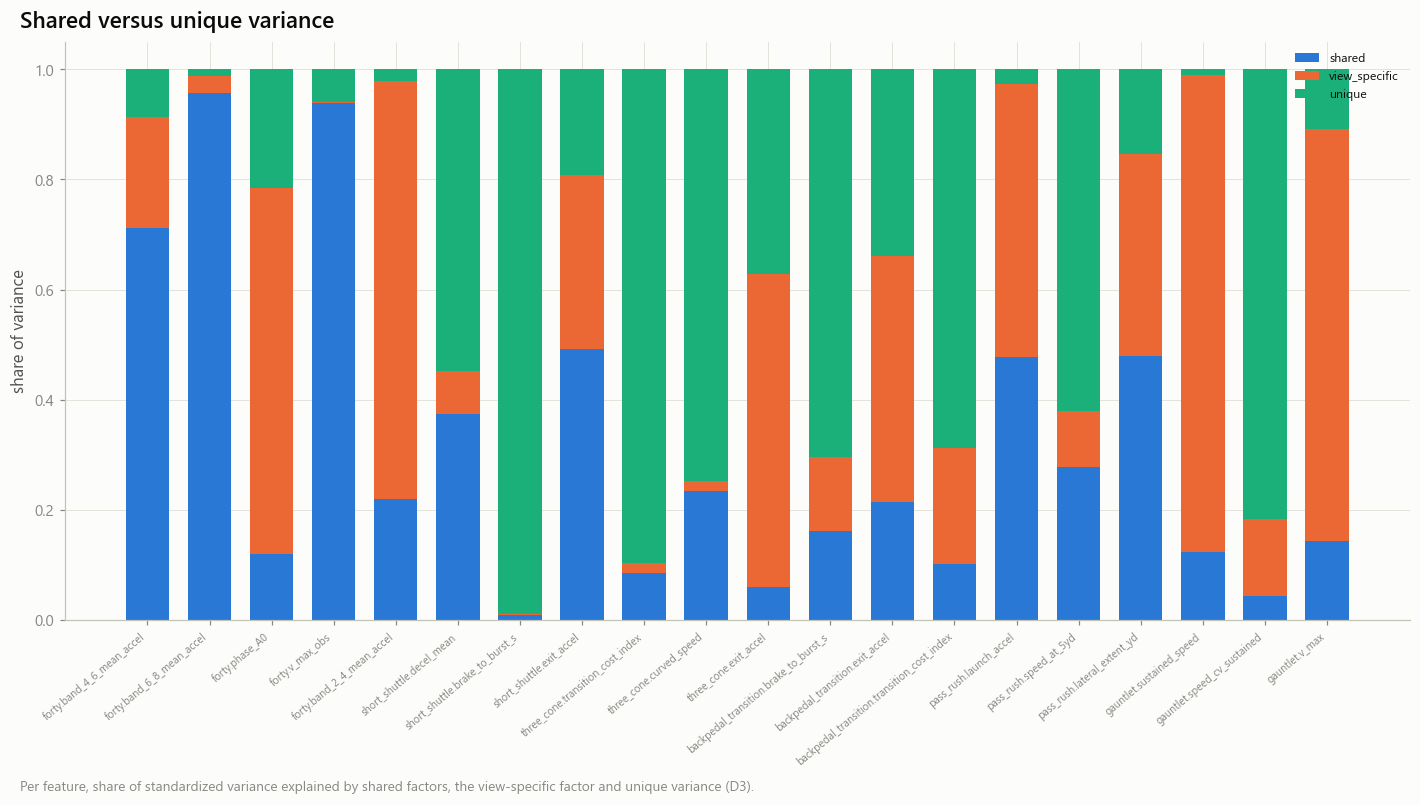

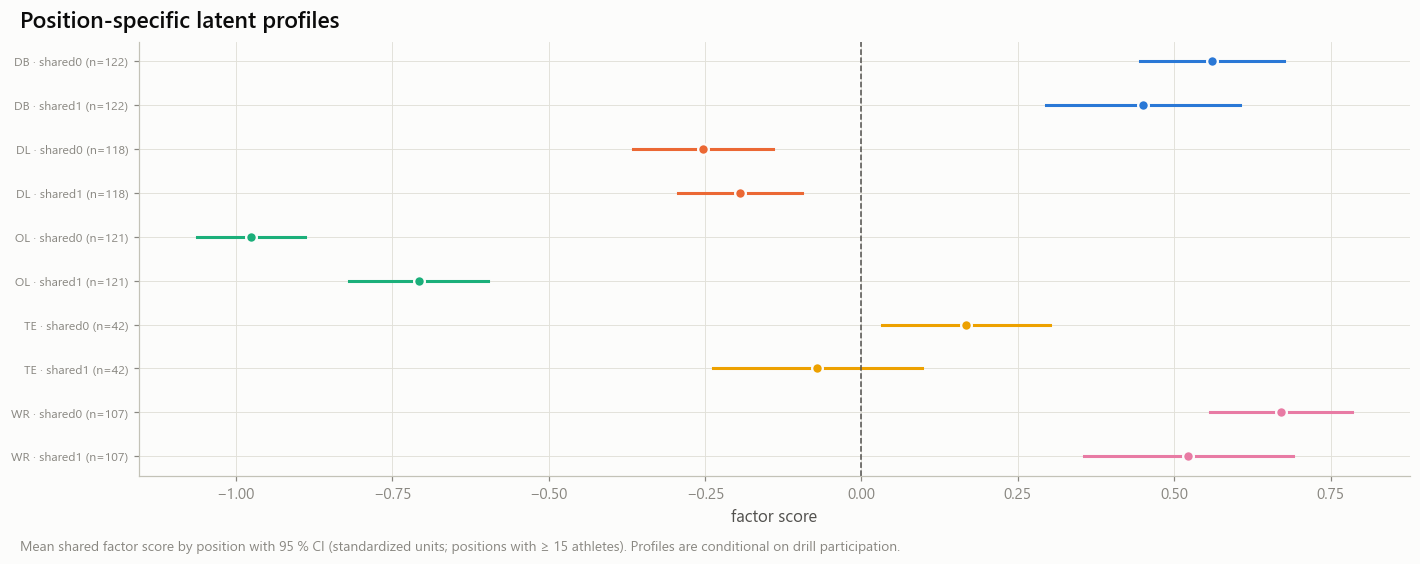

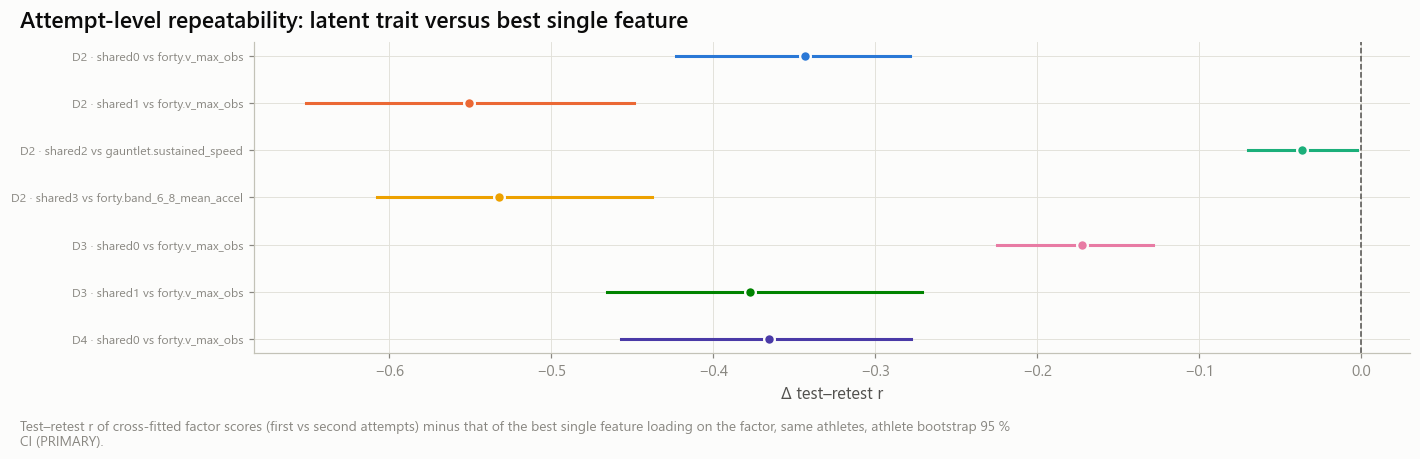

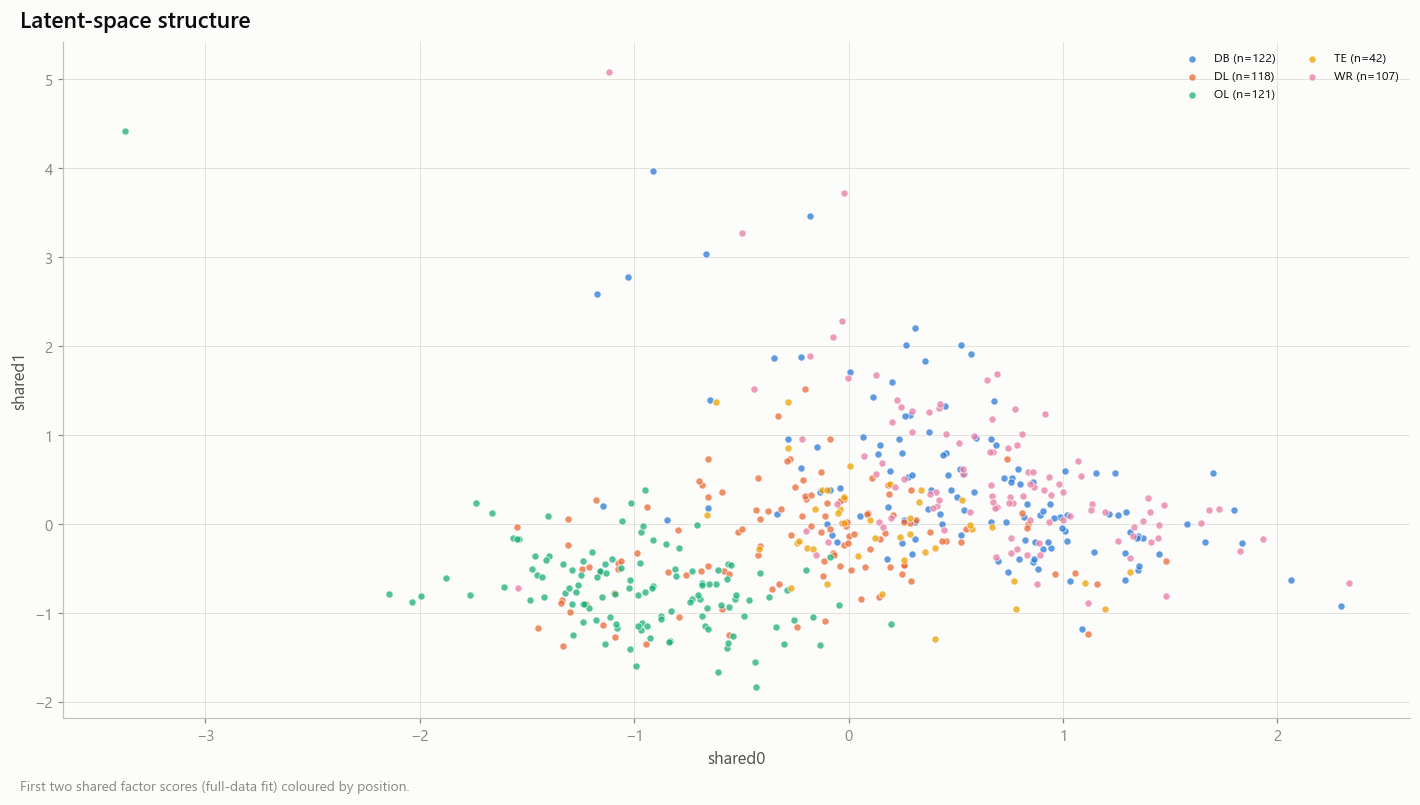

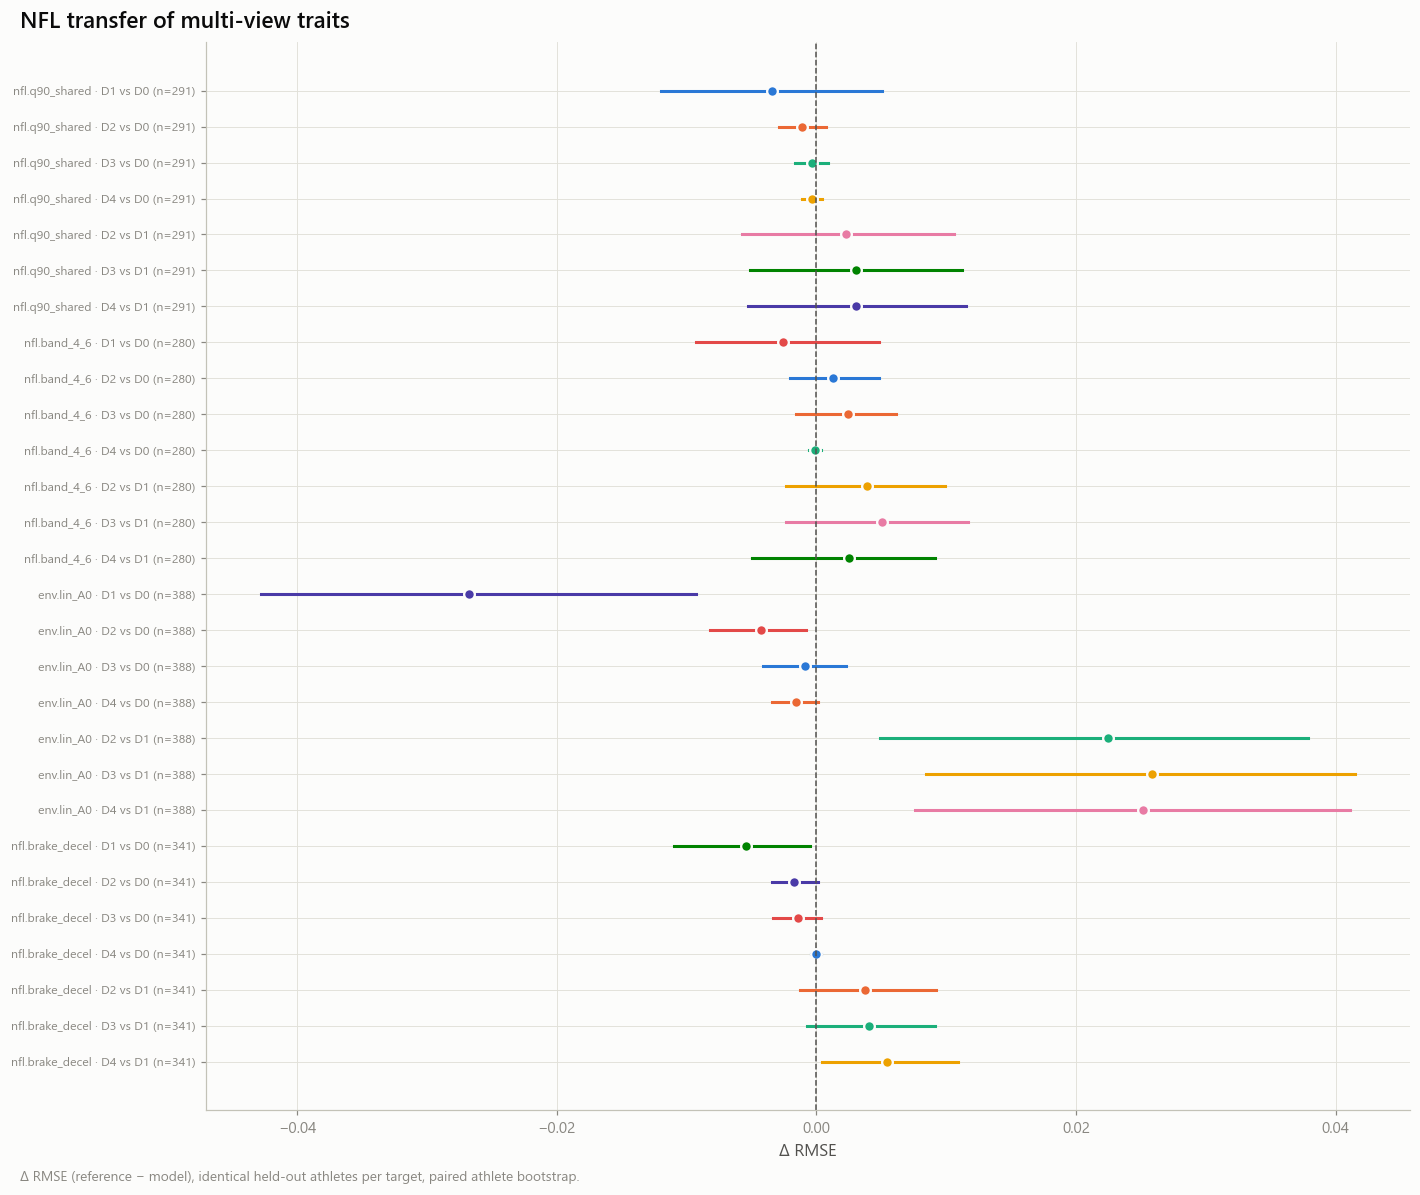

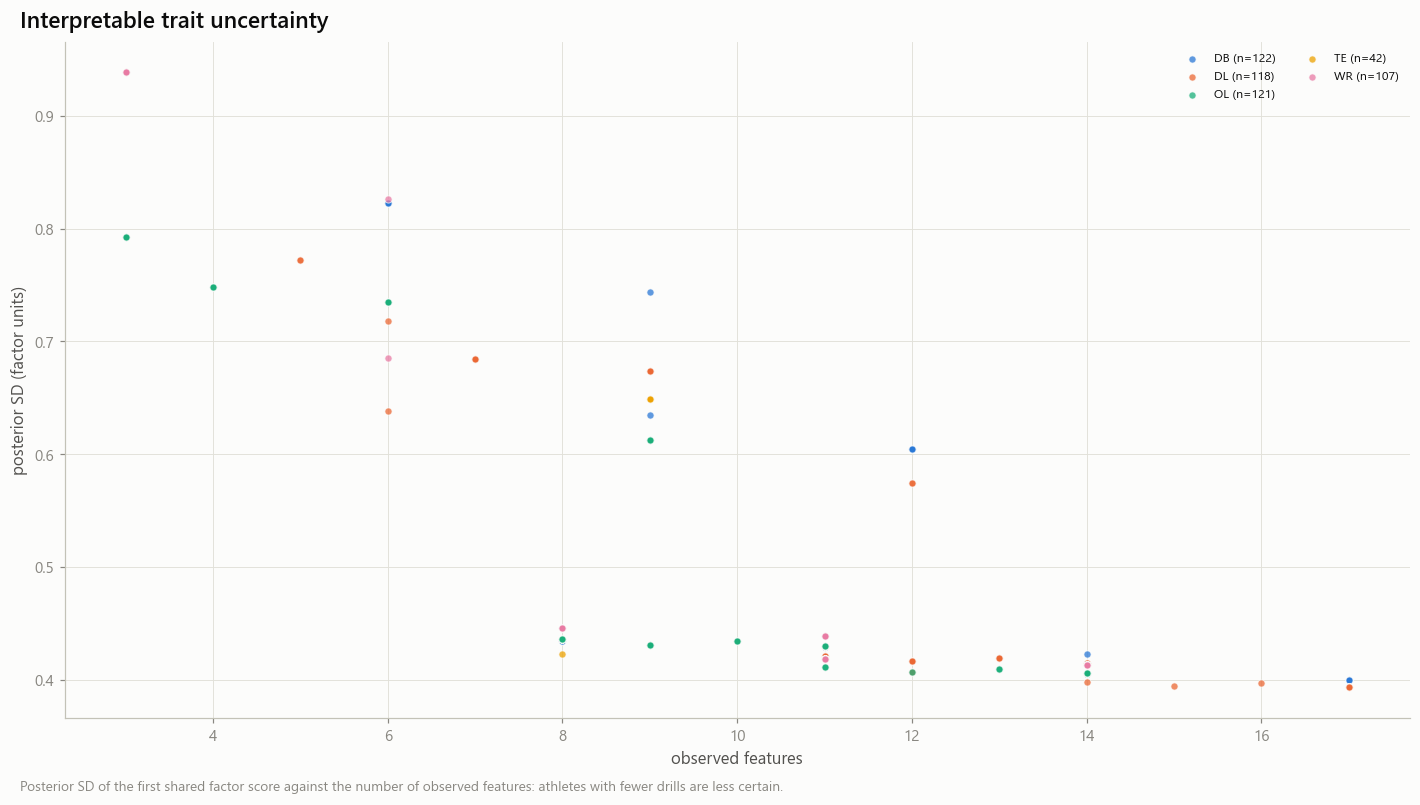

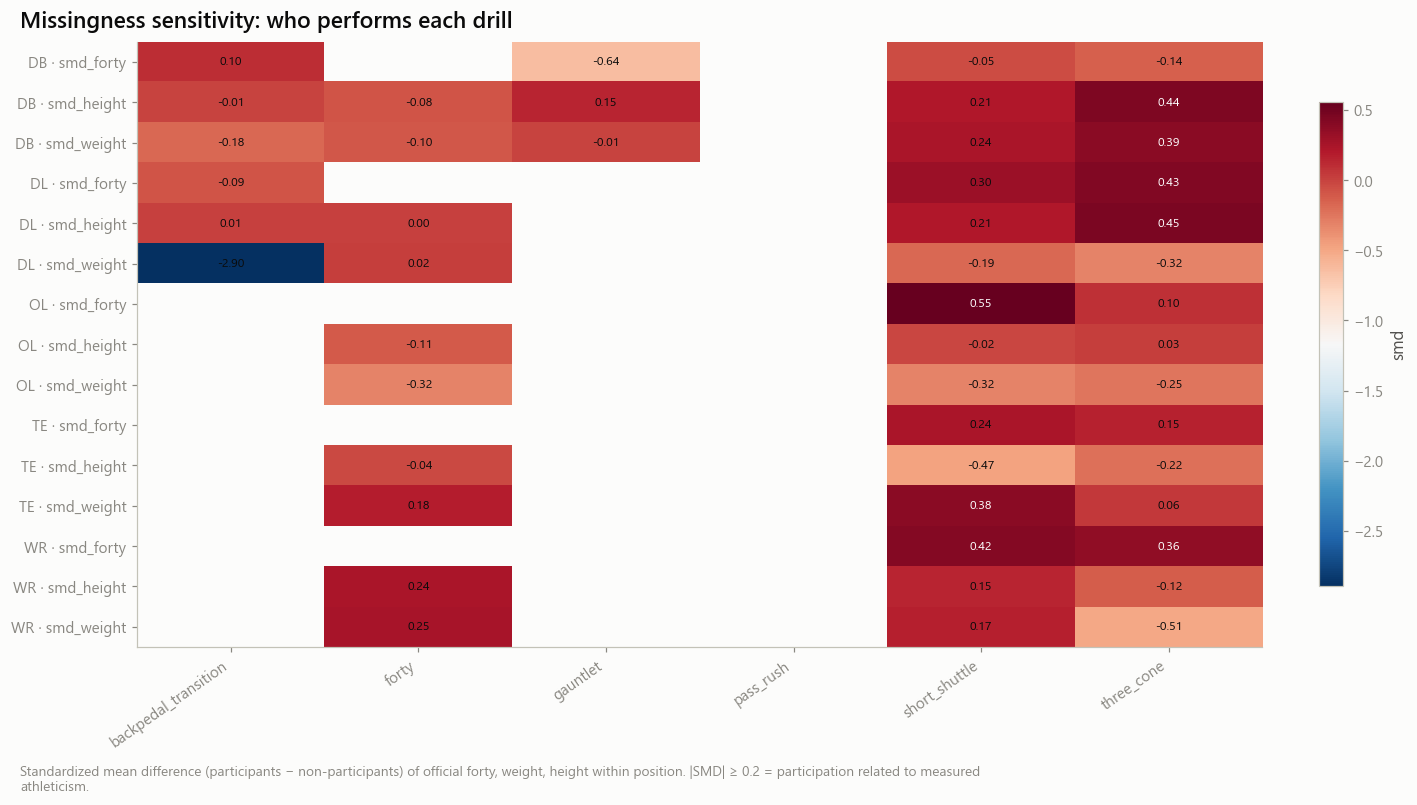

In [7]:
av_long = avail.unpivot(index=['nfl_id', 'position_group'], on=list(views), variable_name='view', value_name='observed').group_by('position_group', 'view').agg(pl.col('observed').mean().alias('participation'))
store.show(fg.fig_heatmap(av_long, 'position_group', 'view', 'participation', 'Multi-view availability', 'Share of athletes per position with a tracked attempt in each view (participation is not random).', fmt='{:.2f}'),
           'AM12_D_01_view_availability', {'availability': av_long}, publication=True, source='m12d_availability')
msel = sel.get('model') or next(iter(fits))
f_ = fits[msel]
store.show(fg.fig_matrix(f_.W, feats, f_.names, f'Factor loading matrix ({msel}, K = {BEST_K[msel]})', 'Standardized loadings of the full-data fit (display; analyses are cross-fitted). Sign convention: largest |loading| positive per factor; factors are not named without support.', 'loading'),
           'AM12_D_02_loading_matrix', {'loadings': load}, publication=True, source='m12d_loadings')
store.show(fg.fig_stacked(vshare.filter(pl.col('model') == msel), 'feature', ['shared', 'view_specific', 'unique'], 'Shared versus unique variance', f'Per feature, share of standardized variance explained by shared factors, the view-specific factor and unique variance ({msel}).', 'share of variance'),
           'AM12_D_03_variance_share', {'variance': vshare}, source='m12d_variance_share')
Sc = f_.scores(mv.position_center(X, pos, np.ones(ids.size, bool)) if msel == 'D4' else X)
ks = [j for j, n in enumerate(f_.names) if n.startswith('shared')]
prof = []
for p in np.unique(pos):
    mm = (pos == p) & np.isfinite(Sc[:, ks[0]])
    if mm.sum() >= 15:
        for q in ks:
            v = Sc[mm, q]
            se = v.std() / np.sqrt(v.size)
            prof.append({'label': f'{p} · {f_.names[q]} (n={int(mm.sum())})', 'position_group': str(p), 'mean': float(v.mean()), 'lo': float(v.mean() - 1.96 * se), 'hi': float(v.mean() + 1.96 * se)})
prof = pl.DataFrame(prof)
store.show(fg.fig_forest(prof, 'label', 'mean', 'lo', 'hi', 'Position-specific latent profiles', 'Mean shared factor score by position with 95 % CI (standardized units; positions with ≥ 15 athletes). Profiles are conditional on drill participation.', 'factor score', color_by='position_group'),
           'AM12_D_04_position_profiles', {'profiles': prof}, source='m12d (full-data fit)')
rr = RET.with_columns((pl.col('model') + ' · ' + pl.col('factor') + ' vs ' + pl.col('best_feature').fill_null('—')).alias('label'))
store.show(fg.fig_forest(rr, 'label', 'gain', 'gain_lo', 'gain_hi', 'Attempt-level repeatability: latent trait versus best single feature', 'Test–retest r of cross-fitted factor scores (first vs second attempts) minus that of the best single feature loading on the factor, same athletes, athlete bootstrap 95 % CI (PRIMARY).',
                         'Δ test–retest r', color_by='model'), 'AM12_D_05_latent_vs_feature_repeatability', {'retest': rr}, publication=True, source='m12d_retest')
if len(ks) >= 2:
    sp = pl.DataFrame({'f0': Sc[:, ks[0]], 'f1': Sc[:, ks[1]], 'position_group': pos})
    store.show(fg.fig_scatter(sp, 'f0', 'f1', 'Latent-space structure', 'First two shared factor scores (full-data fit) coloured by position.', f_.names[ks[0]], f_.names[ks[1]]), 'AM12_D_06_latent_space', {}, source='m12d')
if TR.height:
    tf = TR.with_columns((pl.col('target') + ' · ' + pl.col('model') + ' vs ' + pl.col('reference') + ' (n=' + pl.col('n_athletes').cast(pl.String) + ')').alias('label'))
    store.show(fg.fig_forest(tf, 'label', 'delta_rmse', 'delta_lo', 'delta_hi', 'NFL transfer of multi-view traits', 'Δ RMSE (reference − model), identical held-out athletes per target, paired athlete bootstrap.', 'Δ RMSE', color_by='model'),
               'AM12_D_07_transfer', {'transfer': tf}, publication=True, source='m12d_transfer')
unc = []
Xin_ = mv.position_center(X, pos, np.ones(ids.size, bool)) if msel == 'D4' else X
Z = (Xin_ - f_.center) / f_.scale
for i in range(ids.size):
    o = np.isfinite(Z[i])
    if o.any():
        Minv = np.linalg.inv(np.eye(f_.W.shape[1]) + (f_.W[o].T / f_.psi[o]) @ f_.W[o])
        unc.append({'nfl_id': int(ids[i]), 'position_group': str(pos[i]), 'n_features_observed': int(o.sum()), 'posterior_sd_f0': float(np.sqrt(Minv[ks[0], ks[0]]))})
unc = pl.DataFrame(unc)
W(unc, 'm12d_trait_uncertainty')
store.show(fg.fig_scatter(unc, 'n_features_observed', 'posterior_sd_f0', 'Interpretable trait uncertainty', 'Posterior SD of the first shared factor score against the number of observed features: athletes with fewer drills are less certain.',
                          'observed features', 'posterior SD (factor units)'), 'AM12_D_08_trait_uncertainty', {'uncertainty': unc}, source='m12d')
sm_ = miss.unpivot(index=['position_group', 'view'], on=['smd_forty', 'smd_weight', 'smd_height'], variable_name='official', value_name='smd').with_columns((pl.col('position_group') + ' · ' + pl.col('official')).alias('row'))
store.show(fg.fig_heatmap(sm_, 'row', 'view', 'smd', 'Missingness sensitivity: who performs each drill', 'Standardized mean difference (participants − non-participants) of official forty, weight, height within position. |SMD| ≥ 0.2 = participation related to measured athleticism.', fmt='{:.2f}', cmap='RdBu_r'),
           'AM12_D_09_missingness', {'missingness': sm_}, source='m12d_missingness')

## Part 10–12 · Conclusions, comparisons for 12G, artifacts, next questions

In [8]:
rm = controls.run_mode
comps = [sy.comparison_row('12D', f"retest {r['model']} {r['factor']} vs best feature {r['best_feature']}", 'Δ test–retest r', r['gain'], r['gain_lo'], r['gain_hi'], r['n_athletes'],
                           m12c.RELIABILITY, 'm12d_retest', rm, experiment=4, primary=r['model'] == sel.get('model')) for r in RET.iter_rows(named=True)]
comps += [sy.comparison_row('12D', f"transfer {r['model']} vs {r['reference']} → {r['target']}", 'Δ RMSE', r['delta_rmse'], r['delta_lo'], r['delta_hi'], r['n_athletes'],
                            m12c.PHYSICAL_TRANSFER, 'm12d_transfer', rm, experiment=4) for r in (TR.iter_rows(named=True) if TR.height else [])]
COMP = sy.comparison_frame(comps)
W(COMP, 'm12d_comparisons')
ev_rows = []
for r in RET.iter_rows(named=True):
    t = TR.filter((pl.col('model') == r['model']) & (pl.col('reference') == 'D0')) if TR.height else TR
    t = t.sort('n_athletes', descending=True).row(0, named=True) if t.height else {}
    ev_rows.append(ae.evidence_row(f"12D.{r['model']}.{r['factor']}", '12D', experiment='4', physical_interpretation='shared multi-drill factor (unnamed unless supported)', input_data='m11_athlete_features (views)',
                                   output='factor score', n_athletes=r['n_athletes'], reliability=r['retest_factor'], delta_rmse=t.get('delta_rmse'), delta_lo=t.get('delta_lo'), delta_hi=t.get('delta_hi'),
                                   compute_cost='tens of minutes', evaluation_target=m12c.RELIABILITY, training_regime=m12c.INDUCTIVE, run_mode=rm, config_hash=C.hash()))
EVID = ae.evidence_frame(ev_rows)
W(EVID, 'm12d_evidence')
status = rp.status_from(COMP.filter(pl.col('primary'))['verdict'].to_list())
facts = {'status': status, 'run_mode': rm, 'sample': f'{ids.size} athletes, {len(feats)} features in {len(views)} views; {data.height} linked for transfer.',
         'evidence': [f'K by held-out likelihood: {BEST_K}; selected {sel.get("model")} (K={sel.get("k")})', vae['reason']]
                     + [f"{r['model']} {r['factor']}: retest {rp.fmt(r['retest_factor'])} vs {r['best_feature']} {rp.fmt(r['retest_best_feature'])}, Δ {rp.ci(r['gain'], r['gain_lo'], r['gain_hi'])} (n={r['n_athletes']})" for r in RET.iter_rows(named=True)]
                     + [f"{r['model']} vs {r['reference']} → {r['target']}: Δ RMSE {rp.ci(r['delta_rmse'], r['delta_lo'], r['delta_hi'], 4)} — {r['verdict']}" for r in (TR.iter_rows(named=True) if TR.height else [])],
         'alternatives': ['A higher factor reliability can come from averaging several noisy features (Spearman–Brown), not from a new trait.',
                          'Shared factors may encode position / body size rather than movement mechanics (compare D3 and D4).'],
         'relevance': 'Tells whether several imperfect drills can be combined into one more stable, interpretable physical measurement.',
         'limitations': ['Views are missing not at random.', 'Few repeats per drill.', 'Loadings rotate within the shared block; interpretation only with stability support.'],
         'next': ['If a factor is more reliable but not predictive, use it descriptively (scouting profile), not as an NFL forecast.']}
md = rp.conclusion_markdown('12D', facts)
display(Markdown(md))
rp.write_conclusion(store, '12D', md)
rp.update_doc(store, 'MULTIVIEW_TRAITS.md', md + chr(10) + '### Repeatability (cross-fitted)' + chr(10) + chr(10) + rp.md_table(RET, ['model', 'factor', 'n_athletes', 'retest_factor', 'best_feature', 'retest_best_feature', 'gain', 'gain_lo', 'gain_hi']))
rp.run_manifest(store, '12D', PROV, ['m12d_loglik', 'm12d_retest', 'm12d_loadings', 'm12d_transfer', 'm12d_comparisons', 'm12d_evidence'], status, {'selected': sel})
print('Send back: checks, missingness table, log-likelihood table, retest / stability / position / complete-case tables, the selected representation, transfer table, the conclusion.')
print('Next: 12e_conditional_optimal_transport_matching.ipynb')

## 12D — conclusion (rejected; run mode full; generated 2026-10-15T02:03:00Z)

### Research question
Q4 — Do several drills jointly reveal reproducible physical traits that single drill metrics measure unreliably?

### Declared primary hypothesis
Latent factor scores have higher attempt-split test–retest reliability than the most reliable single tracked feature of their views.

### Primary outcome / comparison
test–retest correlation of factor scores (attempt-split) vs best single feature — D3 structured multi-view FA vs best single feature (evaluation target: `measurement_reliability`)

### Sample
510 athletes, 20 features in 6 views; 401 linked for transfer.

### Main evidence (from persisted tables)
- K by held-out likelihood: {'D2': 4, 'D3': 2, 'D4': 1}; selected D3 (K=2)
- only 0 athletes have every view (< 1000): D5 is not run — a declared rule, not a result
- D2 shared0: retest 0.642 vs forty.v_max_obs 0.985, Δ -0.344 [-0.423, -0.279] (n=375)
- D2 shared1: retest 0.434 vs forty.v_max_obs 0.985, Δ -0.551 [-0.651, -0.449] (n=375)
- D2 shared2: retest 0.704 vs gauntlet.sustained_speed 0.741, Δ -0.037 [-0.070, -0.003] (n=137)
- D2 shared3: retest 0.318 vs forty.band_6_8_mean_accel 0.850, Δ -0.532 [-0.608, -0.438] (n=375)
- D3 shared0: retest 0.813 vs forty.v_max_obs 0.985, Δ -0.172 [-0.225, -0.129] (n=375)
- D3 shared1: retest 0.608 vs forty.v_max_obs 0.985, Δ -0.378 [-0.466, -0.271] (n=375)
- D4 shared0: retest 0.620 vs forty.v_max_obs 0.985, Δ -0.365 [-0.457, -0.278] (n=375)
- D1 vs D0 → nfl.q90_shared: Δ RMSE -0.0034 [-0.0120, 0.0051] — inconclusive
- D2 vs D0 → nfl.q90_shared: Δ RMSE -0.0011 [-0.0029, 0.0007] — inconclusive
- D3 vs D0 → nfl.q90_shared: Δ RMSE -0.0004 [-0.0017, 0.0009] — inconclusive
- D4 vs D0 → nfl.q90_shared: Δ RMSE -0.0004 [-0.0011, 0.0004] — inconclusive
- D2 vs D1 → nfl.q90_shared: Δ RMSE 0.0023 [-0.0057, 0.0106] — inconclusive
- D3 vs D1 → nfl.q90_shared: Δ RMSE 0.0031 [-0.0051, 0.0112] — inconclusive
- D4 vs D1 → nfl.q90_shared: Δ RMSE 0.0031 [-0.0053, 0.0115] — inconclusive
- D1 vs D0 → nfl.band_4_6: Δ RMSE -0.0026 [-0.0093, 0.0049] — inconclusive
- D2 vs D0 → nfl.band_4_6: Δ RMSE 0.0013 [-0.0020, 0.0048] — inconclusive
- D3 vs D0 → nfl.band_4_6: Δ RMSE 0.0024 [-0.0016, 0.0061] — inconclusive
- D4 vs D0 → nfl.band_4_6: Δ RMSE -0.0001 [-0.0005, 0.0004] — inconclusive
- D2 vs D1 → nfl.band_4_6: Δ RMSE 0.0039 [-0.0023, 0.0099] — inconclusive
- D3 vs D1 → nfl.band_4_6: Δ RMSE 0.0050 [-0.0023, 0.0117] — inconclusive
- D4 vs D1 → nfl.band_4_6: Δ RMSE 0.0025 [-0.0050, 0.0092] — inconclusive
- D1 vs D0 → env.lin_A0: Δ RMSE -0.0267 [-0.0428, -0.0092] — model_worse
- D2 vs D0 → env.lin_A0: Δ RMSE -0.0043 [-0.0082, -0.0008] — model_worse
- D3 vs D0 → env.lin_A0: Δ RMSE -0.0009 [-0.0041, 0.0023] — inconclusive
- D4 vs D0 → env.lin_A0: Δ RMSE -0.0016 [-0.0034, 0.0001] — inconclusive
- D2 vs D1 → env.lin_A0: Δ RMSE 0.0224 [0.0049, 0.0379] — model_better
- D3 vs D1 → env.lin_A0: Δ RMSE 0.0258 [0.0084, 0.0415] — model_better
- D4 vs D1 → env.lin_A0: Δ RMSE 0.0251 [0.0076, 0.0411] — model_better
- D1 vs D0 → nfl.brake_decel: Δ RMSE -0.0055 [-0.0110, -0.0005] — model_worse
- D2 vs D0 → nfl.brake_decel: Δ RMSE -0.0017 [-0.0035, 0.0001] — inconclusive
- D3 vs D0 → nfl.brake_decel: Δ RMSE -0.0014 [-0.0033, 0.0004] — inconclusive
- D4 vs D0 → nfl.brake_decel: Δ RMSE -0.0000 [-0.0004, 0.0003] — inconclusive
- D2 vs D1 → nfl.brake_decel: Δ RMSE 0.0038 [-0.0013, 0.0092] — inconclusive
- D3 vs D1 → nfl.brake_decel: Δ RMSE 0.0040 [-0.0007, 0.0092] — inconclusive
- D4 vs D1 → nfl.brake_decel: Δ RMSE 0.0054 [0.0004, 0.0109] — model_better

### Alternative explanations
- A higher factor reliability can come from averaging several noisy features (Spearman–Brown), not from a new trait.
- Shared factors may encode position / body size rather than movement mechanics (compare D3 and D4).

### Practical interpretation
Tells whether several imperfect drills can be combined into one more stable, interpretable physical measurement.

### Limitations
- Views are missing not at random.
- Few repeats per drill.
- Loadings rotate within the shared block; interpretation only with stability support.

### Next research questions
- If a factor is more reliable but not predictive, use it descriptively (scouting profile), not as an NFL forecast.


Send back: checks, missingness table, log-likelihood table, retest / stability / position / complete-case tables, the selected representation, transfer table, the conclusion.
Next: 12e_conditional_optimal_transport_matching.ipynb
